### Environment Setup and Dataset Exploration
We will load the local `dermamnist (1).npz` dataset and check the shapes of the splits (train, validation, test) and labels.

In [1]:
import numpy as np
import tensorflow as tf

# Load the dataset
data_path = '/content/dermamnist (1).npz'
data = np.load(data_path)

# Extract splits
x_train = data['train_images']
y_train = data['train_labels']
x_val = data['val_images']
y_val = data['val_labels']
x_test = data['test_images']
y_test = data['test_labels']

# Display information
print(f"Train images shape: {x_train.shape}, labels shape: {y_train.shape}")
print(f"Validation images shape: {x_val.shape}, labels shape: {y_val.shape}")
print(f"Test images shape: {x_test.shape}, labels shape: {y_test.shape}")
print(f"Unique labels: {np.unique(y_train)}")

Train images shape: (7007, 28, 28, 3), labels shape: (7007, 1)
Validation images shape: (1003, 28, 28, 3), labels shape: (1003, 1)
Test images shape: (2005, 28, 28, 3), labels shape: (2005, 1)
Unique labels: [0 1 2 3 4 5 6]


### Exploratory Data Analysis (EDA)
We will analyze the class balance, image dimensions, verify for missing values, and visualize sample images from each of the 7 classes.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Total and Split Image Counts
total_images = len(x_train) + len(x_val) + len(x_test)
print(f"Total number of images: {total_images}")
print(f"Training images: {len(x_train)}")
print(f"Validation images: {len(x_val)}")
print(f"Testing images: {len(x_test)}\n")

# 2. Check Image Dimensions and Missing Values
print(f"Image dimensions: {x_train.shape[1:3]} with {x_train.shape[3]} channels.")
print(f"Any missing values in train images? {np.isnan(x_train).any()}")
print(f"Any missing values in train labels? {np.isnan(y_train).any()}")

Total number of images: 10015
Training images: 7007
Validation images: 1003
Testing images: 2005

Image dimensions: (28, 28) with 3 channels.
Any missing values in train images? False
Any missing values in train labels? False


Class 0: 228 images (3.25%)
Class 1: 359 images (5.12%)
Class 2: 769 images (10.97%)
Class 3: 80 images (1.14%)
Class 4: 779 images (11.12%)
Class 5: 4693 images (66.98%)
Class 6: 99 images (1.41%)


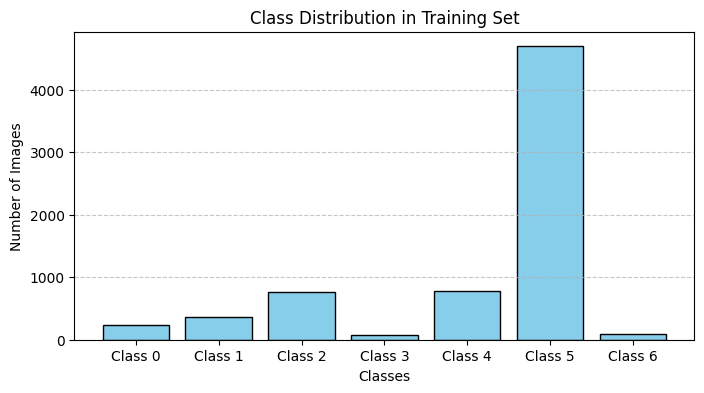

In [4]:
# 3. Class Counts & Bar Chart Distribution
classes, counts = np.unique(y_train, return_counts=True)
class_names = [f"Class {c}" for c in classes]

for name, count in zip(class_names, counts):
    print(f"{name}: {count} images ({count/len(y_train)*100:.2f}%)")

# Plotting distribution
plt.figure(figsize=(8, 4))
plt.bar(class_names, counts, color='skyblue', edgecolor='black')
plt.title("Class Distribution in Training Set")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

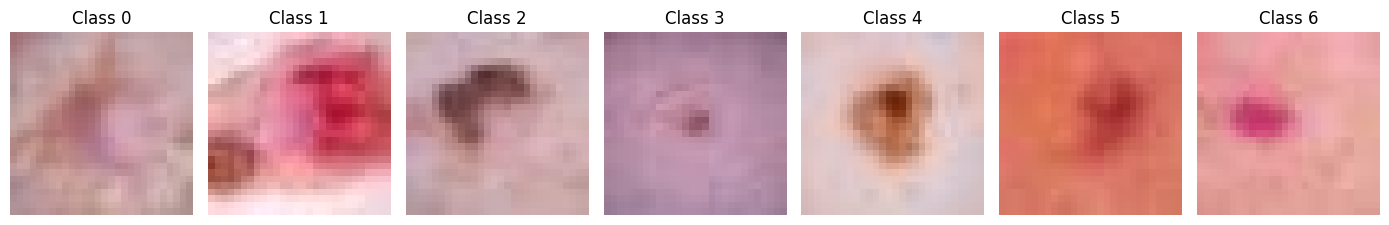

In [5]:
# 4. Display sample images from all 7 classes
plt.figure(figsize=(14, 6))
for target_class in range(7):
    # Find index of the first image belonging to target_class
    idx = np.where(y_train == target_class)[0][0]

    plt.subplot(1, 7, target_class + 1)
    plt.imshow(x_train[idx])
    plt.title(f"Class {target_class}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### Data Preprocessing
We will normalize the images, prepare the train, validation, and test splits, and verify the shapes of the datasets before training.

In [6]:
# 1. Normalize all images by dividing pixel values by 255.0
x_train_preprocessed = x_train.astype('float32') / 255.0
x_val_preprocessed = x_val.astype('float32') / 255.0
x_test_preprocessed = x_test.astype('float32') / 255.0

# 2. Labels are already in integer format (0-6), which is perfect for SparseCategoricalCrossentropy
y_train_preprocessed = y_train
y_val_preprocessed = y_val
y_test_preprocessed = y_test

# 3. Check all dataset shapes and image dimensions (should remain 28x28x3)
print("Preprocessed Dataset Shapes:")
print(f"Train images: {x_train_preprocessed.shape}, Train labels: {y_train_preprocessed.shape}")
print(f"Validation images: {x_val_preprocessed.shape}, Validation labels: {y_val_preprocessed.shape}")
print(f"Test images: {x_test_preprocessed.shape}, Test labels: {y_test_preprocessed.shape}")

# Confirming image shape explicitly
print(f"\nSingle image shape: {x_train_preprocessed[0].shape}")
print(f"Pixel value range: [{x_train_preprocessed.min()}, {x_train_preprocessed.max()}]")

Preprocessed Dataset Shapes:
Train images: (7007, 28, 28, 3), Train labels: (7007, 1)
Validation images: (1003, 28, 28, 3), Validation labels: (1003, 1)
Test images: (2005, 28, 28, 3), Test labels: (2005, 1)

Single image shape: (28, 28, 3)
Pixel value range: [0.0, 1.0]


### Lightweight CNN Model Architecture
We will define the model using the exact layers, filters, and neurons requested to guarantee an ultra-lightweight footprint.

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the lightweight CNN model based on strict requirements
model = models.Sequential([
    # 1. Input layer with shape (28, 28, 3)
    layers.Input(shape=(28, 28, 3)),

    # 2. First Conv2D layer with 8 filters and MaxPooling2D
    layers.Conv2D(8, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # 3. Second Conv2D layer with 16 filters and MaxPooling2D
    layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # 4. Flatten layer
    layers.Flatten(),

    # 5. Dense layer with 32 neurons and Dropout (0.3)
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),

    # 6. Output Dense layer with 7 neurons and softmax activation
    layers.Dense(7, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display summary
model.summary()

# Estimate model footprint
total_params = model.count_params()
estimated_size_kb = (total_params * 4) / 1024  # Assuming float32 (4 bytes per parameter)
print(f"\nTotal Parameters: {total_params:,}")
print(f"Estimated Parameter Size: {estimated_size_kb:.2f} KB")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,743 (104.46 KB)

 Trainable params: 26,743 (104.46 KB)

 Non-trainable params: 0 (0.00 B)


Total Parameters: 26,743
Estimated Parameter Size: 104.46 KB


### Model Training
We will train our compiled lightweight CNN model for 10 epochs using the preprocessed training dataset and validate it with the validation set.

In [8]:
import os

# Train the model
history = model.fit(
    x_train_preprocessed,
    y_train_preprocessed,
    epochs=10,
    batch_size=32,
    validation_data=(x_val_preprocessed, y_val_preprocessed)
)

# Save the trained model in Keras format
model_save_path = 'skin_cancer_model.keras'
model.save(model_save_path)

# Verify saved model size
file_size_mb = os.path.getsize(model_save_path) / (1024 * 1024)
print(f"\nSaved model file size: {file_size_mb:.4f} MB")
assert file_size_mb < 25.0, "Saved model exceeds 25 MB!"

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.6586 - loss: 1.1880 - val_accuracy: 0.6690 - val_loss: 1.0458
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6696 - loss: 1.0454 - val_accuracy: 0.6690 - val_loss: 0.9557
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6695 - loss: 0.9748 - val_accuracy: 0.6690 - val_loss: 0.9062
Epoch 4/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6698 - loss: 0.9513 - val_accuracy: 0.6690 - val_loss: 0.9285
Epoch 5/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6699 - loss: 0.9300 - val_accuracy: 0.6690 - val_loss: 0.8828
Epoch 6/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6705 - loss: 0.9153 - val_accuracy: 0.6720 - val_loss: 0.8957
Epoch 7/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6760 - loss: 0.9026 - val_accuracy: 0.6820 - val_loss: 0.8659
Epoch 8/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6753 - loss: 0.8817 - val_accuracy: 

### Model Evaluation
We will evaluate the trained lightweight model on the test split, visualize the training performance history, and generate a classification report and confusion matrix to analyze the model's predictions across all 7 classes.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Evaluate the model using the test dataset
test_loss, test_acc = model.evaluate(x_test_preprocessed, y_test_preprocessed, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}\n")

Test Loss: 0.8249
Test Accuracy: 0.6738



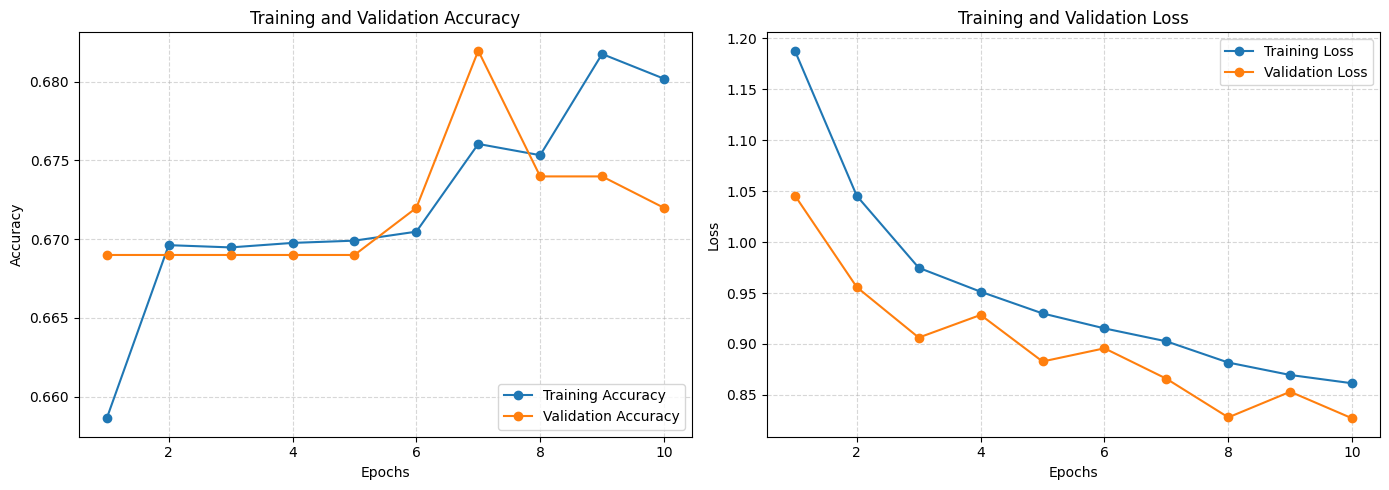

In [10]:
# 2. Plot Training and Validation Accuracy / Loss Graphs
epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Classification Report:
              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00        66
     Class 1       0.00      0.00      0.00       103
     Class 2       0.32      0.05      0.09       220
     Class 3       0.00      0.00      0.00        23
     Class 4       0.00      0.00      0.00       223
     Class 5       0.68      1.00      0.81      1341
     Class 6       0.00      0.00      0.00        29

    accuracy                           0.67      2005
   macro avg       0.14      0.15      0.13      2005
weighted avg       0.49      0.67      0.55      2005



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


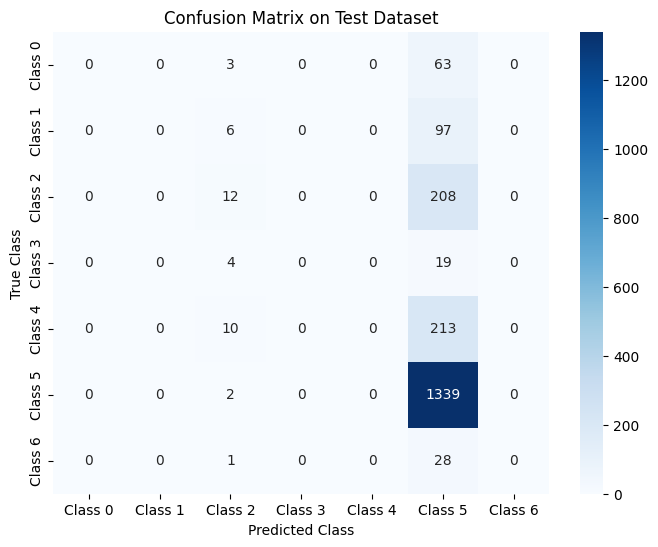

In [11]:
# 3. Generate predictions and class metrics
y_pred_probs = model.predict(x_test_preprocessed)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test_preprocessed.flatten()

# 4. Display Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=[f"Class {i}" for i in range(7)]))

# 5. Generate and plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f"Class {i}" for i in range(7)],
            yticklabels=[f"Class {i}" for i in range(7)])
plt.title('Confusion Matrix on Test Dataset')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

### Build, Train, and Save the Lightweight CNN Model
We will define a simple, lightweight CNN architecture from scratch to ensure the saved model (`skin_cancer_model.keras`) is well under the 25 MB limit.

In [2]:
import os
from tensorflow.keras import layers, models

# Normalize image pixel values to [0, 1]
x_train_norm = x_train.astype('float32') / 255.0
x_val_norm = x_val.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

# Build a lightweight CNN model from scratch
model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(7, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    x_train_norm, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(x_val_norm, y_val)
)

# Save the model in Keras format
model_save_path = 'skin_cancer_model.keras'
model.save(model_save_path)

# Check the file size of the saved model
file_size_mb = os.path.getsize(model_save_path) / (1024 * 1024)
print(f"\nSaved model size: {file_size_mb:.2f} MB")
assert file_size_mb < 25.0, "The saved model size exceeds the 25 MB limit!"

# Evaluate the model on test data
test_loss, test_acc = model.evaluate(x_test_norm, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,543 (1006.03 KB)

 Trainable params: 257,543 (1006.03 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 54ms/step - accuracy: 0.6669 - loss: 1.1045 - val_accuracy: 0.6690 - val_loss: 0.9684
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6699 - loss: 0.9911 - val_accuracy: 0.6690 - val_loss: 0.9228
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6698 - loss: 0.9592 - val_accuracy: 0.6690 - val_loss: 0.8980
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6735 - loss: 0.9291 - val_accuracy: 0.6690 - val_loss: 0.8774
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6765 - loss: 0.8974 - val_accuracy: 0.6830 - val_loss: 0.8693
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6835 - loss: 0.8897 - val_accuracy: 0.6700 - val_loss: 0.8723
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6810 - loss: 0.8848 - val_accuracy: 0.6879 - val_loss: 0.8309
Epoch 8/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6829 - loss: 0.8666 - val_accuracy: 

### Save Model and Provide Download Link
We will save the model in Keras format, confirm that the file size complies with our strict requirements, and generate a download link.

In [12]:
import os
from google.colab import files
import tensorflow as tf

# Save the model in Keras format ensuring the weights are preserved
model_save_path = 'skin_cancer_model.keras'
model.save(model_save_path)

# Programmatically check the file size in MB
file_size_mb = os.path.getsize(model_save_path) / (1024 * 1024)
print(f"Saved Model File: {model_save_path}")
print(f"Saved Model Size: {file_size_mb:.4f} MB")

# Verify tensorflow can load the saved model successfully
try:
    loaded_model = tf.keras.models.load_model(model_save_path)
    print("Validation Success: The saved model can be loaded using tf.keras.models.load_model()!")
except Exception as e:
    print(f"Validation Failed: {e}")

# Trigger browser download for the saved model file
files.download(model_save_path)

Saved Model File: skin_cancer_model.keras
Saved Model Size: 0.3438 MB
Validation Success: The saved model can be loaded using tf.keras.models.load_model()!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>